**Proyecto:** GalMorphAI · Maestría en Inteligencia Artificial Aplicada · Fase CRISP-ML: *Modelado* (modelos alternativos)

> **Resultado:** de siete modelos individuales, los dos mejores fueron el perceptrón multicapa (MLP) y la SVM RBF, sin diferencia demostrable entre ellos. Tras el ajuste se eligió el **MLP ajustado** por parsimonia (PR-AUC en validación 0.759). Es el mejor modelo tabular individual, pero no supera a la CNN ResNet18 de la fase anterior (0.801), que sigue siendo el modelo final del proyecto.

Este avance responde a cinco acciones:

1. Construir al menos 6 modelos **individuales** (no ensambles) con algoritmos variados → `Paso: 2`, `Paso: 3`
2. Comparar su rendimiento → `Paso: 4`
3. Seleccionar los dos mejores → `Paso: 5`
4. Ajustar los dos mejores → `Paso: 6`
5. Elegir el modelo individual final → `Paso: 8`

**Qué cuenta como modelo individual.** Un solo estimador que aprende una sola función: regresión logística, análisis discriminante lineal, Naive Bayes, kNN, árbol de decisión, SVM y perceptrón multicapa. Random Forest, ExtraTrees, HistGradientBoosting, *bagging* y AdaBoost combinan muchos árboles, así que se estudian en el notebook de ensambles.

**Reglas de evaluación.**
- **Datos:** mismas características (FE), misma partición por grupos y mismas 1 464 galaxias de validación que el baseline y la CNN.
- **Métrica principal:** PR-AUC. La clase «barra visible» es ≈ 33 %; PR-AUC no depende del umbral y es sensible a la clase minoritaria. La calibración se mide aparte, con Brier y ECE.
- **Ajuste:** los hiperparámetros se ajustan con validación cruzada por grupos (5 pliegues) dentro del entrenamiento.
- **Decisiones:** la comparación y la elección se hacen en validación, con intervalos *bootstrap* y diferencias pareadas. Las reglas de selección, adopción del ajuste y elección final se fijaron antes de ver los resultados.
- **Prueba:** este notebook **no usa el conjunto de prueba**. Ya se consultó una vez (CNN-14) para evaluar el modelo final del proyecto, y el modelo elegido aquí no lo reemplaza.

**Nota sobre la CNN.** La CNN ResNet18 también es un modelo individual, pero no participa en esta comparación (`INCLUDE_CNN = False`). Se desarrolló y evaluó en su propio notebook y usa otra entrada (imágenes en lugar de características). Aquí solo se usa como referencia en las conclusiones.

## Configuración e importacion de librerias empleadas en el notebook

In [29]:
# Configuración
from pathlib import Path
import sys, io, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import loguniform, randint, uniform
import sklearn
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, brier_score_loss, precision_recall_curve, confusion_matrix)

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

# EDITAR ESTAS RUTAS en tu equipo (las mismas de las fases anteriores)
FE_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/fe')
BL_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/baseline')
CNN_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/cnn')
ALT_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/alternativos')
ALT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_SPLITS_CV = 5
N_BOOTSTRAP = 1000
INCLUDE_CNN = False           # la CNN del notebook anterior compite como un modelo individual más
N_ITER_TUNE = 40             # combinaciones de la búsqueda aleatoria para cada modelo tabular seleccionado
RUN_CNN_TUNING = False        # si la CNN queda entre los dos mejores: ajuste con PyTorch (≈3 h en MPS, reanudable)
FEATURE_MS_PER_IMAGE = 90.0  # costo medido de extraer las características de un FITS (BL-9)
RUN_FINAL_TEST = False       # [ALT-10] solo si el modelo final cambia respecto a CNN-14

random.seed(SEED); np.random.seed(SEED)
CLASS_COLORS = {0: '#2a78d6', 1: '#eb6834'}
NEUTRAL = '#8a8984'
CNN_COLOR = '#6250d6'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold'})
def savefig(name):
    plt.savefig(ALT_DIR / f'{name}.png', bbox_inches='tight')
SKLEARN_GE_18 = tuple(int(x) for x in sklearn.__version__.split('.')[:2]) >= (1, 8)
CNN_NAME = 'CNN ResNet18 (p99.9 + TTA)'
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


## 1.- Datos, partición y funciones de evaluación
Se usan las mismas características y la misma partición del baseline, así cualquier diferencia se debe al algoritmo y no a los datos.

In [30]:
# 1 Datos
data = pd.read_csv(FE_DIR / 'dataset_caracteristicas.csv')
fe_art = joblib.load(FE_DIR / 'transformadores_fe.joblib')
bl_path = BL_DIR / 'modelos_baseline.joblib'
bl = joblib.load(bl_path) if bl_path.exists() else None
if bl is not None:
    FEATURES = bl['features']
    print('Conjunto de características del baseline:', bl['feature_set'], f'({len(FEATURES)})')
else:
    FEATURES = [f for g in fe_art['feature_groups'].values() for f in g if f in data.columns]
    print('Sin artefactos del baseline: todas las características de imagen', f'({len(FEATURES)})')

train = data[data['split'] == 'train'].reset_index(drop=True)
val = data[data['split'] == 'validation'].reset_index(drop=True)
X_tr, y_tr, g_tr = train[FEATURES], train['label'].to_numpy(), train['group_id'].to_numpy()
X_va, y_va = val[FEATURES], val['label'].to_numpy()
CV_SPLITS = list(StratifiedGroupKFold(n_splits=N_SPLITS_CV, shuffle=True, random_state=SEED).split(X_tr, y_tr, groups=g_tr))
labels_va = pd.Series(y_va, index=val['name'])
print(f'Entrenamiento {len(train)} · validación {len(val)} (prevalencia {y_va.mean():.3f}) · prueba: no se usa')

# CNN  (predicciones calibradas con TTA en validación)
cnn_val = None
if INCLUDE_CNN and (BL_DIR / 'predicciones_validacion_cnn.csv').exists():
    cnn_val = pd.read_csv(BL_DIR / 'predicciones_validacion_cnn.csv').set_index('name')['score'].reindex(val['name'])
    cnn_final = joblib.load(CNN_DIR / 'cnn_final.joblib')
    if cnn_val.isna().any():
        print(f'⚠ {cnn_val.isna().sum()} galaxias de validación sin predicción de la CNN: se comparan solo las comunes')
    print('CNN incluida como candidato individual.')
elif INCLUDE_CNN:
    print('⚠ No se encontró predicciones_validacion_cnn.csv: la comparación se hace solo con modelos tabulares.')
INCLUDE_CNN = cnn_val is not None

Conjunto de características del baseline: all (34)
Entrenamiento 6823 · validación 1464 (prevalencia 0.333) · prueba: no se usa


In [31]:
# 1.1.- Funciones de evaluación 
def ece_score(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    return sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(n_bins) if (idx == b).any())

def bootstrap_ci(y, p, n=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            vals.append(average_precision_score(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])]) if len(thr) else 0.5

def full_metrics(y, p, thr):
    pred = (p >= thr).astype(int); lo, hi = bootstrap_ci(y, p)
    return {'PR_AUC': average_precision_score(y, p), 'PR_AUC_IC95_inf': lo, 'PR_AUC_IC95_sup': hi,
            'ROC_AUC': roc_auc_score(y, p), 'umbral': thr, 'F1_barra': f1_score(y, pred, zero_division=0),
            'precision_barra': precision_score(y, pred, zero_division=0), 'recall_barra': recall_score(y, pred, zero_division=0),
            'exactitud_bal': balanced_accuracy_score(y, pred), 'Brier': brier_score_loss(y, p), 'ECE': ece_score(y, p)}

def paired_bootstrap(sa, sb, labels, n=N_BOOTSTRAP, seed=SEED):
    common = sa.dropna().index.intersection(sb.dropna().index).intersection(labels.index)
    pa, pb_, y = sa[common].to_numpy(), sb[common].to_numpy(), labels[common].to_numpy()
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            d.append(average_precision_score(y[i], pa[i]) - average_precision_score(y[i], pb_[i]))
    return average_precision_score(y, pa) - average_precision_score(y, pb_), tuple(np.percentile(d, [2.5, 97.5])), len(common)

def verdict(lo, hi, a='A', b='B'):
    return f'{a} mejor' if lo > 0 else f'{b} mejor' if hi < 0 else 'sin diferencia demostrable'

def model_mb(obj):
    buf = io.BytesIO(); joblib.dump(obj, buf); return buf.getbuffer().nbytes / 1024**2

def ms_per_image(model, n=500):
    Xs = X_va.iloc[:n]; t0 = time.perf_counter(); model.predict_proba(Xs)
    return (time.perf_counter() - t0) / len(Xs) * 1000

def fold_scores(oof):
    """PR-AUC de cada pliegue a partir de las predicciones fuera de pliegue (mismos CV_SPLITS)."""
    return np.array([average_precision_score(y_tr[te], oof[te]) for _, te in CV_SPLITS])

## 2.- Catálogo de modelos individuales
Ocho algoritmos tabulares de familias distintas. En esta etapa cada uno usa una **configuración razonable por defecto**, sin ajuste: el objetivo es comparar algoritmos en igualdad de condiciones. El ajuste se reserva para los dos mejores.

1. **Regresión logística**
   - Familia: lineal, discriminativo
   - Qué supone o aprende: frontera lineal en las características
   - Configuración inicial: L2, C = 1
2. **Análisis discriminante lineal (LDA)**
   - Familia: lineal, generativo
   - Qué supone o aprende: clases gaussianas con covarianza común
   - Configuración inicial: *shrinkage* automático (Ledoit-Wolf)
3. **Naive Bayes gaussiano**
   - Familia: probabilístico, generativo
   - Qué supone o aprende: características independientes dada la clase
   - Configuración inicial: por defecto
4. **k vecinos más cercanos (kNN)**
   - Familia: basado en instancias
   - Qué supone o aprende: similitud local en el espacio de características
   - Configuración inicial: k = 25, ponderado por distancia
5. **Árbol de decisión**
   - Familia: reglas jerárquicas
   - Qué supone o aprende: cortes por umbral; captura interacciones
   - Configuración inicial: profundidad 8, hoja ≥ 20
6. **SVM con kernel RBF**
   - Familia: margen máximo, no lineal
   - Qué supone o aprende: frontera no lineal suave
   - Configuración inicial: C = 1, gamma = 'scale'
7. **Perceptrón multicapa (MLP)**
   - Familia: red neuronal
   - Qué supone o aprende: combinaciones no lineales de las características
   - Configuración inicial: capas (64, 32), *early stopping*

**Preprocesamiento dentro de cada `Pipeline`** (se ajusta en cada pliegue, sin fuga): imputación por mediana y, en los modelos sensibles a la escala o a la forma de la distribución, Yeo-Johnson con estandarización. El árbol solo imputa. **Desbalance:** `class_weight='balanced'` donde el algoritmo lo admite; LDA, Naive Bayes, kNN y MLP no lo admiten, pero PR-AUC no depende del umbral y el umbral se ajusta después con F1.

In [32]:
# 2.- Definición de los modelos
def scaled(clf):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('yj', PowerTransformer()), ('clf', clf)])
def unscaled(clf):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('clf', clf)])

CANDIDATES = {
    'Regresión logística': scaled(LogisticRegression(C=1.0, class_weight='balanced', max_iter=5000, random_state=SEED)),
    'Análisis discriminante lineal': scaled(LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')),
    'Naive Bayes gaussiano': scaled(GaussianNB()),
    'kNN': scaled(KNeighborsClassifier(n_neighbors=25, weights='distance')),
    'Árbol de decisión': unscaled(DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight='balanced', random_state=SEED)),
    'SVM RBF': scaled(SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced', random_state=SEED)),
    'Perceptrón multicapa (MLP)': scaled(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=600, early_stopping=True,
                                                       n_iter_no_change=15, random_state=SEED)),
}
def with_proba(name, est):
    """La SVM no da probabilidades: se calibra con Platt (CV interna) solo para Brier/ECE; no cambia el orden de forma relevante."""
    return CalibratedClassifierCV(est, method='sigmoid', cv=5, ensemble=False) if name == 'SVM RBF' else est
FAMILY = {'Regresión logística': 'lineal', 'Análisis discriminante lineal': 'lineal', 'Naive Bayes gaussiano': 'probabilístico',
          'kNN': 'instancias', 'Árbol de decisión': 'árbol', 'SVM RBF': 'kernel', 'Perceptrón multicapa (MLP)': 'red neuronal',
          CNN_NAME: 'red convolucional (imagen)'}
print(f'{len(CANDIDATES)} modelos tabulares individuales' + (' + CNN' if INCLUDE_CNN else ''))

7 modelos tabulares individuales


## 3.- Entrenamiento y evaluación de cada modelo
Para cada modelo tabular:
- **Validación cruzada por grupos** (5 pliegues) en entrenamiento: predicciones fuera de pliegue (OOF), PR-AUC medio y su desviación entre pliegues.
- **Brecha de sobreajuste:** PR-AUC en el propio entrenamiento menos PR-AUC en CV.
- **Umbral:** el que maximiza F1 de «barra visible» en las predicciones OOF (nunca en validación).
- **Validación:** el modelo reentrenado con todo el entrenamiento se evalúa en las 1 464 galaxias de validación.
- **Costos:** tiempo de entrenamiento, tamaño y milisegundos por imagen.

La CNN se incorpora con sus predicciones de validación ejecutados en un notebook distinto para agilizar el proceso (umbral y temperatura elegidos en `train_es`).

In [33]:
# 3.- Entrenamiento y evaluación (etapa 1: configuración por defecto)
stage1_models, OOF, VAL, THR, rows = {}, {}, {}, {}, []
for name, pipe in CANDIDATES.items():
    est = with_proba(name, clone(pipe))
    t0 = time.perf_counter(); est.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    oof = cross_val_predict(with_proba(name, clone(pipe)), X_tr, y_tr, cv=CV_SPLITS, method='predict_proba')[:, 1]
    fs = fold_scores(oof)
    stage1_models[name], OOF[name] = est, oof
    THR[name] = best_f1_threshold(y_tr, oof)
    VAL[name] = pd.Series(est.predict_proba(X_va)[:, 1], index=val['name'])
    rows.append({'modelo': name, 'familia': FAMILY[name], 'PR_AUC_cv_media': fs.mean(), 'PR_AUC_cv_std': fs.std(),
                 'brecha_train_cv': average_precision_score(y_tr, est.predict_proba(X_tr)[:, 1]) - fs.mean(),
                 **full_metrics(y_va, VAL[name].to_numpy(), THR[name]),
                 'seg_entrenamiento': fit_s, 'MB_modelo': model_mb(est),
                 'ms_por_imagen': FEATURE_MS_PER_IMAGE + ms_per_image(est)})
    print(f'{name:<32} CV {fs.mean():.4f} ± {fs.std():.4f} · validación {rows[-1]["PR_AUC"]:.4f} · {fit_s:.1f} s')

if INCLUDE_CNN:
    rc = pd.read_csv(CNN_DIR / 'recursos_cnn.csv', index_col=0) if (CNN_DIR / 'recursos_cnn.csv').exists() else None
    def rc_get(key, default=np.nan):
        try: return float(rc.loc[key].iloc[0])
        except Exception: return default
    cnn_ms = rc_get('ms_por_1000_pred_mps') / 1000 + rc_get('ms_preprocesamiento_por_imagen', 0.0)
    mask = cnn_val.notna().to_numpy()
    VAL[CNN_NAME] = cnn_val
    THR[CNN_NAME] = float(cnn_final['threshold'])
    rows.append({'modelo': CNN_NAME, 'familia': FAMILY[CNN_NAME], 'PR_AUC_cv_media': np.nan, 'PR_AUC_cv_std': np.nan,
                 'brecha_train_cv': np.nan, **full_metrics(y_va[mask], cnn_val.to_numpy()[mask], THR[CNN_NAME]),
                 'seg_entrenamiento': rc_get('min_entrenamiento_por_corrida') * 60, 'MB_modelo': rc_get('MB_modelo'),
                 'ms_por_imagen': cnn_ms})
stage1 = pd.DataFrame(rows).set_index('modelo').sort_values('PR_AUC', ascending=False)
display(stage1[['familia', 'PR_AUC_cv_media', 'PR_AUC_cv_std', 'brecha_train_cv', 'PR_AUC', 'PR_AUC_IC95_inf', 'PR_AUC_IC95_sup',
                'ROC_AUC', 'F1_barra', 'exactitud_bal', 'Brier', 'ECE']].round(4))
stage1.to_csv(ALT_DIR / 'comparacion_modelos_individuales.csv')

Regresión logística              CV 0.7037 ± 0.0128 · validación 0.7072 · 0.7 s
Análisis discriminante lineal    CV 0.7042 ± 0.0145 · validación 0.7049 · 0.7 s
Naive Bayes gaussiano            CV 0.6547 ± 0.0161 · validación 0.6453 · 0.6 s
kNN                              CV 0.7137 ± 0.0182 · validación 0.7049 · 0.7 s
Árbol de decisión                CV 0.6669 ± 0.0136 · validación 0.6520 · 0.1 s
SVM RBF                          CV 0.7576 ± 0.0125 · validación 0.7614 · 8.2 s
Perceptrón multicapa (MLP)       CV 0.7590 ± 0.0108 · validación 0.7672 · 1.2 s


,familia,PR_AUC_cv_media,PR_AUC_cv_std,brecha_train_cv,PR_AUC,PR_AUC_IC95_inf,PR_AUC_IC95_sup,ROC_AUC,F1_barra,exactitud_bal,Brier,ECE
modelo,,,,,,,,,,,,
Perceptrón multicapa (MLP),red neuronal,0.7590,0.0108,0.0789,0.7672,0.7277,0.8012,0.8538,0.6717,0.7544,0.1439,0.0422
SVM RBF,kernel,0.7576,0.0125,0.0564,0.7614,0.7231,0.7951,0.8517,0.6809,0.7622,0.1438,0.0267
Regresión logística,lineal,0.7037,0.0128,0.0041,0.7072,0.6666,0.7452,0.8119,0.6385,0.7258,0.1751,0.1157
kNN,instancias,0.7137,0.0182,0.2863,0.7049,0.6643,0.7446,0.8168,0.6467,0.7330,0.1591,0.0204
Análisis discriminante lineal,lineal,0.7042,0.0145,0.0052,0.7049,0.6645,0.7423,0.8063,0.6401,0.7283,0.1610,0.0276
Árbol de decisión,árbol,0.6669,0.0136,0.1077,0.6520,0.6107,0.6921,0.7896,0.6099,0.7047,0.1909,0.1267
Naive Bayes gaussiano,probabilístico,0.6547,0.0161,0.0031,0.6453,0.6021,0.6871,0.7712,0.6038,0.6966,0.2005,0.1415


## 4.- Comparación del rendimiento
**Métrica principal: PR-AUC** (la clase «barra visible» es ≈ 33 %; PR-AUC no depende del umbral y es sensible a la clase minoritaria). Se reportan además ROC-AUC, F1 y exactitud balanceada con el umbral elegido en entrenamiento, y Brier/ECE para la **calibración** (si la puntuación se puede leer como probabilidad), que es una pregunta distinta a la calidad de clasificación.

Para saber si dos modelos difieren de verdad se usa la **diferencia pareada por *bootstrap*** sobre las mismas galaxias: si su IC 95 % excluye 0, la diferencia es demostrable.

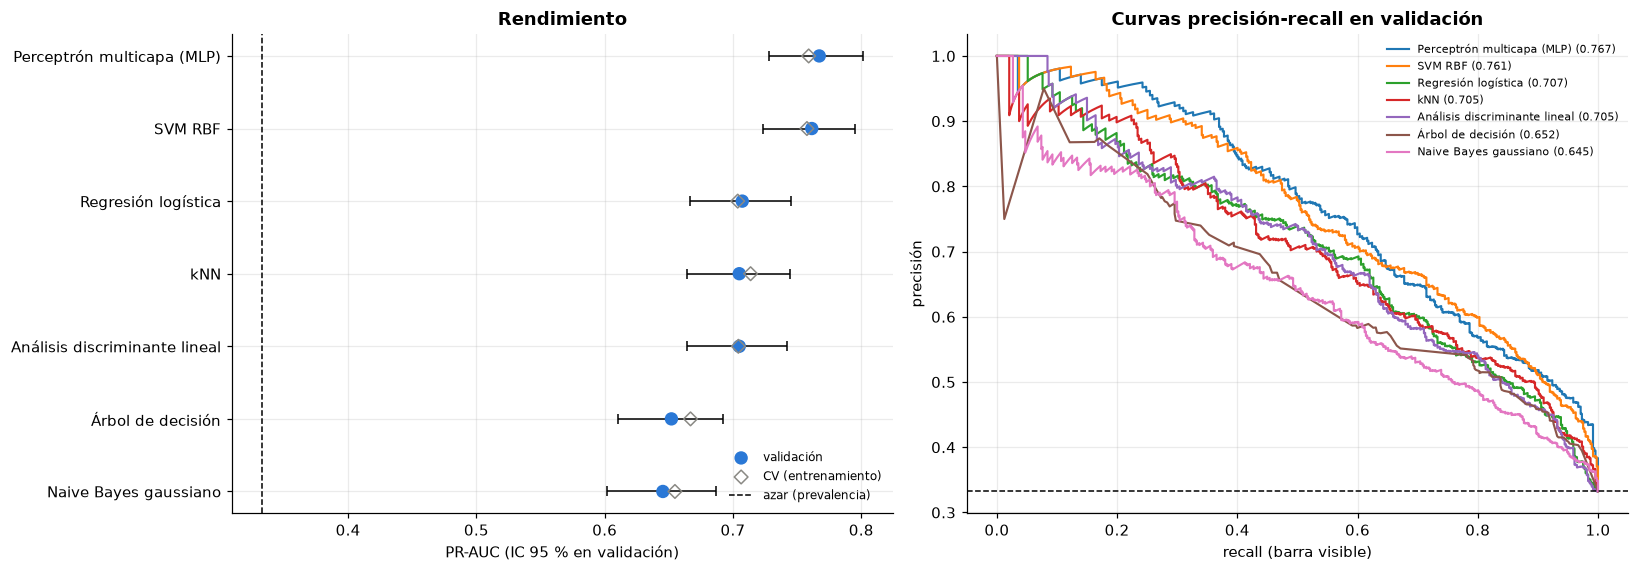

In [34]:
# 4.- Gráficas de comparación
order = stage1.sort_values('PR_AUC').index
colors = [CNN_COLOR if n == CNN_NAME else CLASS_COLORS[0] for n in order]
fig, axes = plt.subplots(1, 2, figsize=(15, 0.5 * len(order) + 1.8))
yy = np.arange(len(order)); s = stage1.loc[order]
axes[0].errorbar(s['PR_AUC'], yy, xerr=[s['PR_AUC'] - s['PR_AUC_IC95_inf'], s['PR_AUC_IC95_sup'] - s['PR_AUC']],
                 fmt='none', ecolor='black', capsize=3, lw=1)
axes[0].scatter(s['PR_AUC'], yy, s=60, color=colors, zorder=3, label='validación')
axes[0].scatter(s['PR_AUC_cv_media'], yy, s=40, marker='D', facecolors='none', edgecolors=NEUTRAL, zorder=3, label='CV (entrenamiento)')
axes[0].axvline(y_va.mean(), ls='--', color='black', lw=1, label='azar (prevalencia)')
axes[0].set_yticks(yy, order); axes[0].set_xlabel('PR-AUC (IC 95 % en validación)'); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title('Rendimiento')
for n in order[::-1]:
    sc = VAL[n].dropna(); pr, rc_, _ = precision_recall_curve(labels_va[sc.index], sc)
    axes[1].plot(rc_, pr, lw=2.2 if n == CNN_NAME else 1.4, color=CNN_COLOR if n == CNN_NAME else None, label=f'{n} ({stage1.loc[n, "PR_AUC"]:.3f})')
axes[1].axhline(y_va.mean(), ls='--', color='black', lw=1)
axes[1].set_xlabel('recall (barra visible)'); axes[1].set_ylabel('precisión'); axes[1].legend(frameon=False, fontsize=7)
axes[1].set_title('Curvas precisión-recall en validación')
plt.tight_layout(); savefig('alt4_comparacion'); plt.show()

In [35]:
# 4.1.- ¿Las diferencias con el mejor son demostrables? (bootstrap pareado en validación)
best_name = stage1.index[0]
cmp_rows = []
for n in stage1.index[1:]:
    d, (lo, hi), k = paired_bootstrap(VAL[best_name], VAL[n], labels_va)
    cmp_rows.append({'modelo': n, f'Δ PR-AUC ({best_name} − modelo)': d, 'IC95_inf': lo, 'IC95_sup': hi, 'n': k,
                     'conclusión': 'peor que el mejor' if lo > 0 else 'sin diferencia demostrable con el mejor'})
cmp1 = pd.DataFrame(cmp_rows).set_index('modelo')
print('Mejor modelo en validación:', best_name); display(cmp1.round(4))
cmp1.to_csv(ALT_DIR / 'comparacion_pareada_etapa1.csv')

Mejor modelo en validación: Perceptrón multicapa (MLP)


,Δ PR-AUC (Perceptrón multicapa (MLP) − modelo),IC95_inf,IC95_sup,n,conclusión
modelo,,,,,
SVM RBF,0.0058,-0.0088,0.0196,1464,sin diferencia demostrable con el mejor
Regresión logística,0.0600,0.0333,0.0862,1464,peor que el mejor
kNN,0.0624,0.0355,0.0886,1464,peor que el mejor
Análisis discriminante lineal,0.0624,0.0357,0.0884,1464,peor que el mejor
Árbol de decisión,0.1152,0.0832,0.1468,1464,peor que el mejor
Naive Bayes gaussiano,0.1219,0.0897,0.1545,1464,peor que el mejor


In [36]:
# 4.2.- Costos y sobreajuste (medidas blandas)
display(stage1[['familia', 'seg_entrenamiento', 'MB_modelo', 'ms_por_imagen', 'brecha_train_cv', 'PR_AUC_cv_std']].round(3))
print('ms_por_imagen incluye la extracción de características (~90 ms) en los modelos tabulares; en la CNN incluye la preparación de la entrada.')

,familia,seg_entrenamiento,MB_modelo,ms_por_imagen,brecha_train_cv,PR_AUC_cv_std
modelo,,,,,,
Perceptrón multicapa (MLP),red neuronal,1.223,0.111,90.006,0.079,0.011
SVM RBF,kernel,8.178,1.084,90.199,0.056,0.012
Regresión logística,lineal,0.746,0.004,90.005,0.004,0.013
kNN,instancias,0.698,1.826,90.021,0.286,0.018
Análisis discriminante lineal,lineal,0.670,0.013,90.008,0.005,0.015
Árbol de decisión,árbol,0.138,0.019,90.002,0.108,0.014
Naive Bayes gaussiano,probabilístico,0.645,0.005,90.006,0.003,0.016


ms_por_imagen incluye la extracción de características (~90 ms) en los modelos tabulares; en la CNN incluye la preparación de la entrada.


## 5.- Selección de los dos mejores modelos
**Regla (fijada antes de ver resultados):** se seleccionan los dos modelos con mayor PR-AUC en validación. Se usa validación porque es el único conjunto que comparten la CNN y los modelos tabulares; el PR-AUC de CV se muestra para comprobar que el orden de los tabulares es estable.

In [37]:
# 5.- Selección
TOP2 = list(stage1.index[:2])
print('Dos mejores modelos:', TOP2)
for n in TOP2:
    r = stage1.loc[n]
    print(f'  {n}: validación {r.PR_AUC:.4f} [{r.PR_AUC_IC95_inf:.3f}, {r.PR_AUC_IC95_sup:.3f}] · CV {r.PR_AUC_cv_media:.4f}')
third = stage1.index[2]
d, (lo, hi), _ = paired_bootstrap(VAL[TOP2[1]], VAL[third], labels_va)
print(f'Segundo frente al tercero ({third}): Δ {d:+.4f} [{lo:+.4f}, {hi:+.4f}] → '
      f'{"segundo demostrablemente mejor" if lo > 0 else "sin diferencia demostrable: la selección del segundo es frágil"}')
tab_rank = stage1.drop(index=[CNN_NAME], errors='ignore')
print('Orden de los tabulares por CV:', list(tab_rank.sort_values('PR_AUC_cv_media', ascending=False).index[:3]),
      '| por validación:', list(tab_rank.index[:3]))
CNN_IN_TOP2 = CNN_NAME in TOP2
TAB_TOP = [n for n in TOP2 if n != CNN_NAME]

Dos mejores modelos: ['Perceptrón multicapa (MLP)', 'SVM RBF']
  Perceptrón multicapa (MLP): validación 0.7672 [0.728, 0.801] · CV 0.7590
  SVM RBF: validación 0.7614 [0.723, 0.795] · CV 0.7576
Segundo frente al tercero (Regresión logística): Δ +0.0542 [+0.0304, +0.0788] → segundo demostrablemente mejor
Orden de los tabulares por CV: ['Perceptrón multicapa (MLP)', 'SVM RBF', 'kNN'] | por validación: ['Perceptrón multicapa (MLP)', 'SVM RBF', 'Regresión logística']


## 6.- Ajuste de los modelos tabulares seleccionados
Búsqueda aleatoria (`RandomizedSearchCV`) con `N_ITER_TUNE` combinaciones, los mismos 5 pliegues por grupos y PR-AUC. Las escalas (C, gamma, alpha, tasas de aprendizaje, regularización) se muestrean de forma log-uniforme: con el mismo presupuesto, la búsqueda aleatoria explora mejor que una rejilla los hiperparámetros que importan (Bergstra y Bengio, 2012).

**Hiperparámetros explorados por modelo:**
- **Regresión logística:** C; mezcla L1/L2 (*elastic net*)
- **LDA:** intensidad del *shrinkage*
- **Naive Bayes:** suavizado de varianza
- **kNN:** k, ponderación, métrica (Manhattan o euclidiana)
- **Árbol de decisión:** profundidad, tamaño de hoja, criterio, poda por complejidad
- **SVM RBF:** C, gamma
- **MLP:** arquitectura, regularización L2 (alpha), tasa de aprendizaje, activación

**Regla de adopción:** la versión ajustada reemplaza a la inicial solo si su PR-AUC en CV mejora en promedio más que el error estándar de la diferencia entre pliegues (comparación pareada pliegue a pliegue). El mejor valor de una búsqueda es optimista, porque es el máximo de muchas combinaciones; por eso después se verifica en validación.

In [38]:
# 6.- Espacios de búsqueda y ajuste
lr_kwargs = dict(solver='saga', max_iter=5000, class_weight='balanced', random_state=SEED)
if not SKLEARN_GE_18:
    lr_kwargs['penalty'] = 'elasticnet'      # en scikit-learn < 1.8 l1_ratio solo se aplica con penalty='elasticnet'
TUNE_SPACES = {
    'Regresión logística': (scaled(LogisticRegression(l1_ratio=0.5, **lr_kwargs)),
        {'clf__C': loguniform(1e-3, 1e2), 'clf__l1_ratio': uniform(0, 1)}),
    'Análisis discriminante lineal': (scaled(LinearDiscriminantAnalysis(solver='lsqr')),
        {'clf__shrinkage': uniform(0, 1)}),
    'Naive Bayes gaussiano': (scaled(GaussianNB()),
        {'clf__var_smoothing': loguniform(1e-12, 1e0)}),
    'kNN': (scaled(KNeighborsClassifier()),
        {'clf__n_neighbors': randint(5, 201), 'clf__weights': ['uniform', 'distance'], 'clf__p': [1, 2]}),
    'Árbol de decisión': (unscaled(DecisionTreeClassifier(class_weight='balanced', random_state=SEED)),
        {'clf__max_depth': [3, 4, 5, 6, 8, 10, 12, 16, None], 'clf__min_samples_leaf': randint(5, 151),
         'clf__criterion': ['gini', 'entropy'], 'clf__ccp_alpha': loguniform(1e-5, 1e-2)}),
    'SVM RBF': (scaled(SVC(kernel='rbf', class_weight='balanced', random_state=SEED)),
        {'clf__C': loguniform(1e-1, 1e2), 'clf__gamma': loguniform(1e-3, 3e-1)}),
    'Perceptrón multicapa (MLP)': (scaled(MLPClassifier(max_iter=600, early_stopping=True, n_iter_no_change=15, random_state=SEED)),
        {'clf__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64), (128, 64, 32)],
         'clf__alpha': loguniform(1e-5, 1e-1), 'clf__learning_rate_init': loguniform(1e-4, 1e-2),
         'clf__activation': ['relu', 'tanh']}),
}
cache_file = ALT_DIR / 'busquedas_top2.joblib'
cached = joblib.load(cache_file) if cache_file.exists() else {}
tuned, tune_rows = {}, []
for name in TAB_TOP:
    pipe, space = TUNE_SPACES[name]
    if name in cached and len(cached[name].cv_results_['params']) == N_ITER_TUNE:
        rs = cached[name]; print(f'{name}: búsqueda cargada de disco')
    else:
        t0 = time.perf_counter()
        rs = RandomizedSearchCV(pipe, space, n_iter=N_ITER_TUNE, scoring='average_precision', cv=CV_SPLITS,
                                n_jobs=-1, random_state=SEED, refit=True, return_train_score=True).fit(X_tr, y_tr)
        rs.elapsed_ = time.perf_counter() - t0
        cached[name] = rs; joblib.dump(cached, cache_file)
    i = rs.best_index_
    f_tuned = np.array([rs.cv_results_[f'split{k}_test_score'][i] for k in range(N_SPLITS_CV)])
    f_def = fold_scores(OOF[name])
    diff = f_tuned - f_def
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    adopt = diff.mean() > se
    tuned[name] = {'search': rs, 'adopt': adopt}
    tune_rows.append({'modelo': name, 'PR_AUC_cv_inicial': f_def.mean(), 'PR_AUC_cv_ajustado': f_tuned.mean(),
                      'mejora_media': diff.mean(), 'error_estándar': se, 'pliegues_que_mejoran': int((diff > 0).sum()),
                      'brecha_train_cv_ajustado': rs.cv_results_['mean_train_score'][i] - f_tuned.mean(),
                      'combinaciones': len(rs.cv_results_['params']), 'seg_búsqueda': getattr(rs, 'elapsed_', np.nan),
                      'se_adopta': adopt,
                      'mejores_hiperparámetros': {k.replace('clf__', ''): (round(v, 5) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}})
tune_tab = pd.DataFrame(tune_rows).set_index('modelo') if tune_rows else pd.DataFrame()
if len(tune_tab):
    display(tune_tab.round(4)); tune_tab.to_csv(ALT_DIR / 'ajuste_modelos_tabulares.csv')
    json.dump({n: {k: (v if isinstance(v, (str, int, float, type(None), list, tuple)) else float(v)) for k, v in t['search'].best_params_.items()}
               for n, t in tuned.items()}, open(ALT_DIR / 'mejores_hiperparametros.json', 'w'), indent=1, default=str)
else:
    print('Ningún modelo tabular entre los dos mejores.')

Perceptrón multicapa (MLP): búsqueda cargada de disco
SVM RBF: búsqueda cargada de disco


,PR_AUC_cv_inicial,PR_AUC_cv_ajustado,mejora_media,error_estándar,pliegues_que_mejoran,brecha_train_cv_ajustado,combinaciones,seg_búsqueda,se_adopta,mejores_hiperparámetros
modelo,,,,,,,,,,
Perceptrón multicapa (MLP),0.7590,0.7671,0.0081,0.0070,3,0.0467,40,39.4830,True,"{'activation': 'relu', 'alpha': 0.07706, 'hidd..."
SVM RBF,0.7576,0.7610,0.0034,0.0041,3,0.0694,40,97.3955,False,"{'C': 30.63462, 'gamma': 0.00765}"


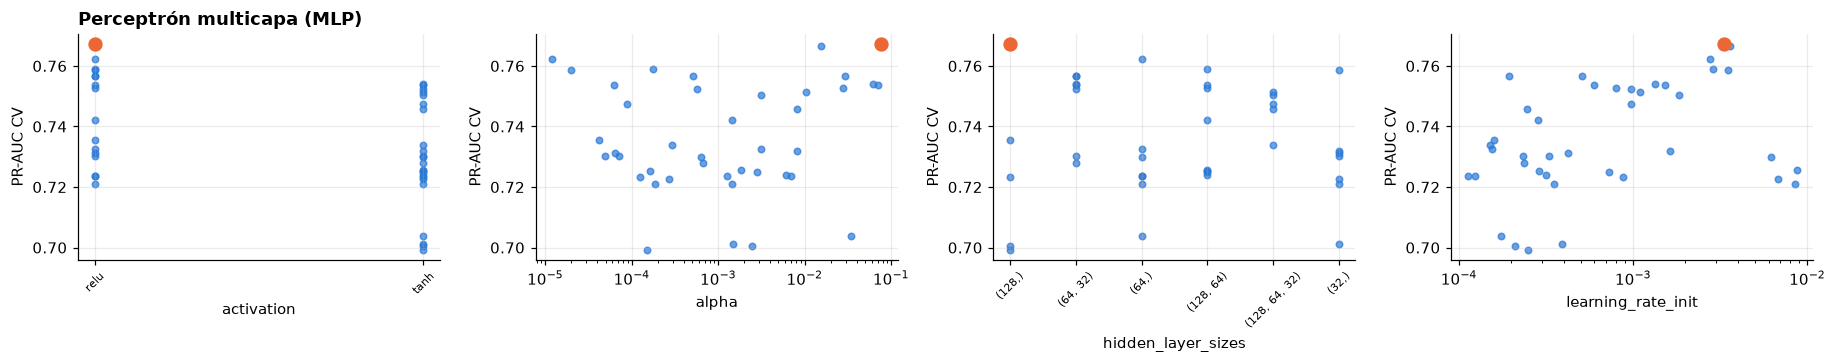

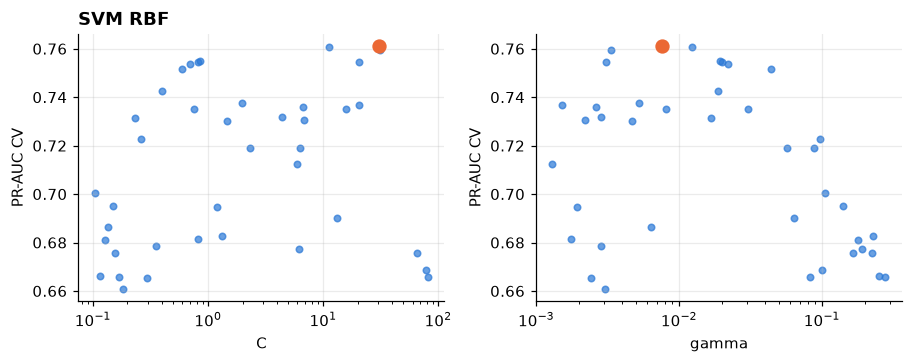

In [39]:
# 6.1.- Sensibilidad: PR-AUC en CV frente a cada hiperparámetro explorado
LOG_PARAMS = {'C', 'gamma', 'alpha', 'learning_rate_init', 'var_smoothing', 'ccp_alpha'}
for name, t in tuned.items():
    res = pd.DataFrame(t['search'].cv_results_)
    params = [c for c in res.columns if c.startswith('param_')]
    fig, axes = plt.subplots(1, len(params), figsize=(4.2 * len(params), 3.4), squeeze=False)
    for ax, col in zip(axes[0], params):
        raw = res[col]
        is_num = raw.map(lambda v: isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool)).all()
        x = raw.astype(float) if is_num else raw.astype(str)
        ax.scatter(x, res['mean_test_score'], s=18, color=CLASS_COLORS[0], alpha=.7)
        ax.scatter([x.iloc[t['search'].best_index_]], [res['mean_test_score'].iloc[t['search'].best_index_]], s=70, color=CLASS_COLORS[1], zorder=3)
        if is_num and col.replace('param_clf__', '') in LOG_PARAMS: ax.set_xscale('log')
        if not is_num: ax.tick_params(axis='x', labelrotation=45, labelsize=7)
        ax.set_xlabel(col.replace('param_clf__', '')); ax.set_ylabel('PR-AUC CV')
    axes[0, 0].set_title(name, loc='left')
    plt.tight_layout(); savefig(f'alt6_sensibilidad_{name.split()[0].lower()}'); plt.show()

Perceptrón multicapa (MLP) (ajustado): PR-AUC CV (OOF) 0.7651 · validación 0.7591
SVM RBF (inicial; el ajuste no mejoró): PR-AUC CV (OOF) 0.7568 · validación 0.7614
Perceptrón multicapa (MLP): brecha final 0.035 · ganancia CV del 80 % al 100 % +0.004
SVM RBF: brecha final 0.058 · ganancia CV del 80 % al 100 % +0.008


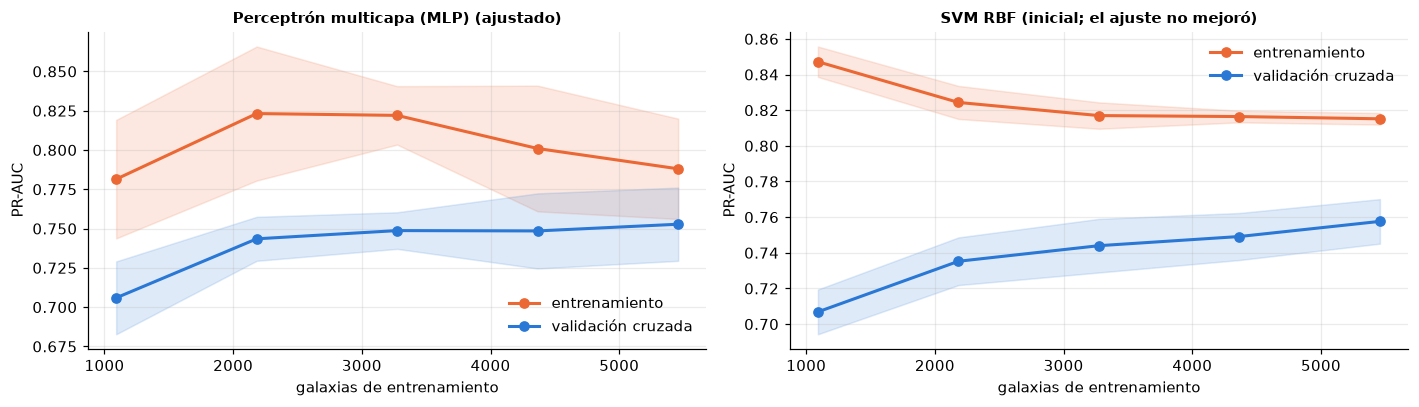

In [40]:
# 6.2.- Versión adoptada de cada modelo tabular seleccionado: OOF, umbral, validación y curva de aprendizaje
FINAL_TAB = {}
for name in TAB_TOP:
    t = tuned[name]
    if t['adopt']:
        base = t['search'].best_estimator_
        est = with_proba(name, clone(base)).fit(X_tr, y_tr)
        oof = cross_val_predict(with_proba(name, clone(base)), X_tr, y_tr, cv=CV_SPLITS, method='predict_proba')[:, 1]
        label = f'{name} (ajustado)'
    else:
        est, oof, label = stage1_models[name], OOF[name], f'{name} (inicial; el ajuste no mejoró)'
    FINAL_TAB[name] = {'est': est, 'oof': oof, 'thr': best_f1_threshold(y_tr, oof), 'label': label,
                       'val': pd.Series(est.predict_proba(X_va)[:, 1], index=val['name'])}
    print(f'{label}: PR-AUC CV (OOF) {average_precision_score(y_tr, oof):.4f} · validación {average_precision_score(y_va, FINAL_TAB[name]["val"]):.4f}')

if FINAL_TAB:
    fig, axes = plt.subplots(1, len(FINAL_TAB), figsize=(6.5 * len(FINAL_TAB), 3.8), squeeze=False)
    for ax, (name, f) in zip(axes[0], FINAL_TAB.items()):
        base = f['est'].estimator if isinstance(f['est'], CalibratedClassifierCV) else f['est']
        sizes, tr_sc, cv_sc = learning_curve(clone(base), X_tr, y_tr, groups=g_tr, cv=CV_SPLITS, scoring='average_precision',
                                             train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1, shuffle=True, random_state=SEED)
        for sc, col, lab in [(tr_sc, CLASS_COLORS[1], 'entrenamiento'), (cv_sc, CLASS_COLORS[0], 'validación cruzada')]:
            ax.plot(sizes, sc.mean(1), 'o-', color=col, lw=2, label=lab)
            ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=col, alpha=.15)
        ax.set_xlabel('galaxias de entrenamiento'); ax.set_ylabel('PR-AUC'); ax.legend(frameon=False); ax.set_title(f['label'], fontsize=10)
        print(f'{name}: brecha final {tr_sc.mean(1)[-1] - cv_sc.mean(1)[-1]:.3f} · ganancia CV del 80 % al 100 % {cv_sc.mean(1)[-1] - cv_sc.mean(1)[-2]:+.3f}')
    plt.tight_layout(); savefig('alt6_curvas_aprendizaje'); plt.show()

## 7.- Elección del modelo individual final
Se comparan en validación las versiones adoptadas de los dos modelos seleccionados (y, como referencia, sus versiones iniciales).

**Regla de elección (fijada de antemano):**
1. Si la diferencia pareada de PR-AUC entre los dos tiene un IC 95 % que excluye 0, se elige el de mayor PR-AUC.
2. Si no es demostrable, se elige el más **parsimonioso**: menor costo por imagen y menor tamaño, y luego el más interpretable. Un modelo más complejo debe justificar su costo con una mejora demostrable.

Nota: validación ya se usó para seleccionar los dos mejores, así que su PR-AUC para el elegido es ligeramente optimista. La estimación sin sesgo es la de prueba.

In [45]:
# 8.- Comparación final y elección
finalists = {}
for n in TOP2:
    if n == CNN_NAME:
        finalists[n] = {'val': CNN_FINAL['val'], 'thr': CNN_FINAL['thr'], 'label': CNN_FINAL['label'],
                        'MB': stage1.loc[n, 'MB_modelo'], 'ms': stage1.loc[n, 'ms_por_imagen'], 'interpretable': False}
    else:
        f = FINAL_TAB[n]
        finalists[n] = {'val': f['val'], 'thr': f['thr'], 'label': f['label'], 'MB': model_mb(f['est']),
                        'ms': FEATURE_MS_PER_IMAGE + ms_per_image(f['est']), 'interpretable': n in ('Regresión logística', 'Análisis discriminante lineal', 'Árbol de decisión', 'Naive Bayes gaussiano')}
rows = []
for n, f in finalists.items():
    sc = f['val'].dropna(); y = labels_va[sc.index].to_numpy()
    rows.append({'modelo': f['label'], 'candidato': n, **full_metrics(y, sc.to_numpy(), f['thr']),
                 'PR_AUC_etapa1': stage1.loc[n, 'PR_AUC'], 'MB_modelo': f['MB'], 'ms_por_imagen': f['ms']})
final_tab = pd.DataFrame(rows).set_index('modelo')
display(final_tab.round(4)); final_tab.to_csv(ALT_DIR / 'eleccion_modelo_final.csv')

a, b = TOP2
d, (lo, hi), n = paired_bootstrap(finalists[a]['val'], finalists[b]['val'], labels_va)
print(f'Δ PR-AUC ({a} − {b}) = {d:+.4f}  IC95 [{lo:+.4f}, {hi:+.4f}]  (n={n}) → {verdict(lo, hi, a, b)}')
if lo > 0 or hi < 0:
    FINAL_MODEL = a if lo > 0 else b
    reason = 'mayor PR-AUC con diferencia demostrable'
else:
    nz = lambda v: np.inf if pd.isna(v) else v
    FINAL_MODEL = min(TOP2, key=lambda k: (nz(finalists[k]['ms']), nz(finalists[k]['MB']), not finalists[k]['interpretable']))
    reason = 'diferencia no demostrable: se elige el más parsimonioso (menor costo y tamaño)'
FINAL_LABEL = finalists[FINAL_MODEL]['label']
print(f'\nMODELO INDIVIDUAL FINAL: {FINAL_LABEL}\nMotivo: {reason}')

,candidato,PR_AUC,PR_AUC_IC95_inf,PR_AUC_IC95_sup,ROC_AUC,umbral,F1_barra,precision_barra,recall_barra,exactitud_bal,Brier,ECE,PR_AUC_etapa1,MB_modelo,ms_por_imagen
modelo,,,,,,,,,,,,,,,
Perceptrón multicapa (MLP) (ajustado),Perceptrón multicapa (MLP),0.7591,0.7205,0.7929,0.8484,0.2958,0.6786,0.6029,0.7762,0.7607,0.1456,0.0357,0.7672,0.1163,90.015
SVM RBF (inicial; el ajuste no mejoró),SVM RBF,0.7614,0.7231,0.7951,0.8517,0.3260,0.6809,0.6210,0.7536,0.7622,0.1438,0.0267,0.7614,1.0837,90.203


Δ PR-AUC (Perceptrón multicapa (MLP) − SVM RBF) = -0.0023  IC95 [-0.0176, +0.0129]  (n=1464) → sin diferencia demostrable

MODELO INDIVIDUAL FINAL: Perceptrón multicapa (MLP) (ajustado)
Motivo: diferencia no demostrable: se elige el más parsimonioso (menor costo y tamaño)


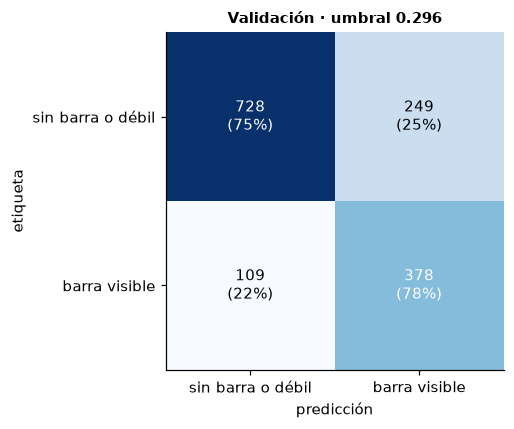

Perceptrón multicapa (MLP) (ajustado): precisión 0.603 · recall 0.776 · F1 0.679


In [46]:
# 8.1.- Matriz de confusión y métricas del modelo final con su umbral (validación)
f = finalists[FINAL_MODEL]; sc = f['val'].dropna(); y = labels_va[sc.index].to_numpy()
pred = (sc.to_numpy() >= f['thr']).astype(int)
cm = confusion_matrix(y, pred)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap='Blues'); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['sin barra o débil', 'barra visible']); ax.set_yticks([0, 1], ['sin barra o débil', 'barra visible'])
ax.set_xlabel('predicción'); ax.set_ylabel('etiqueta'); ax.set_title(f'Validación · umbral {f["thr"]:.3f}', fontsize=10)
plt.tight_layout(); savefig('alt8_confusion_final'); plt.show()
print(f'{FINAL_LABEL}: precisión {precision_score(y, pred):.3f} · recall {recall_score(y, pred):.3f} · F1 {f1_score(y, pred):.3f}')

## 8.- Guardado de artefactos
Además de la elección, se guardan los siete modelos tabulares (versión adoptada de cada uno), sus predicciones fuera de pliegue y de validación: el notebook de ensambles los usa como modelos base.

In [48]:
# 9.- Guardado
models_out, oof_out, val_out, thr_out, cv_rows = {}, {}, {}, {}, []
for name in CANDIDATES:
    if name in FINAL_TAB:
        est, oof, vs, thr = FINAL_TAB[name]['est'], FINAL_TAB[name]['oof'], FINAL_TAB[name]['val'], FINAL_TAB[name]['thr']
    else:
        est, oof, vs, thr = stage1_models[name], OOF[name], VAL[name], THR[name]
    models_out[name], oof_out[name], val_out[name], thr_out[name] = est, oof, vs, thr
    fs = fold_scores(oof)
    cv_rows.append({'modelo': name, 'PR_AUC_cv_media': fs.mean(), 'PR_AUC_cv_std': fs.std(),
                    'brecha_train_cv': average_precision_score(y_tr, est.predict_proba(X_tr)[:, 1]) - fs.mean(),
                    'ajustado': name in FINAL_TAB and tuned[name]['adopt']})
pd.DataFrame(cv_rows).set_index('modelo').to_csv(ALT_DIR / 'busqueda_tabular_cv.csv')
pd.DataFrame({'name': train['name'], 'label': y_tr, **{f'oof__{n}': v for n, v in oof_out.items()}}).to_csv(ALT_DIR / 'oof_entrenamiento_alternativos.csv', index=False)
pd.DataFrame({'name': val['name'], 'label': y_va, **{f'score__{n}': v.to_numpy() for n, v in val_out.items()}}).to_csv(ALT_DIR / 'predicciones_validacion_alternativos.csv', index=False)
joblib.dump({'models': models_out, 'thresholds': thr_out, 'features': FEATURES,
             'best_params': {n: t['search'].best_params_ for n, t in tuned.items()},
             'top2': TOP2, 'final_model': FINAL_MODEL, 'final_label': FINAL_LABEL, 'final_is_cnn': FINAL_MODEL == CNN_NAME,
             'cnn_tuning_adopted': ADOPT_NEW, 'stage1': stage1}, ALT_DIR / 'modelos_alternativos.joblib')
json.dump({'top2': TOP2, 'modelo_final': FINAL_LABEL, 'motivo': reason}, open(ALT_DIR / 'modelo_individual_final.json', 'w'), ensure_ascii=False, indent=1)
print('Guardado en', ALT_DIR)
for p in sorted(ALT_DIR.glob('*')):
    if p.is_file():
        print('  ', p.name)

Guardado en /Users/geo/Proyecto_Integrador/Modelos/alternativos
   ajuste_modelos_tabulares.csv
   alt4_comparacion.png
   alt6_curvas_aprendizaje.png
   alt6_sensibilidad_perceptrón.png
   alt6_sensibilidad_svm.png
   alt8_confusion_final.png
   busqueda_tabular_cv.csv
   busquedas_top2.joblib
   comparacion_modelos_individuales.csv
   comparacion_pareada_etapa1.csv
   eleccion_modelo_final.csv
   mejores_hiperparametros.json
   modelo_individual_final.json
   modelos_alternativos.joblib
   oof_entrenamiento_alternativos.csv
   predicciones_validacion_alternativos.csv


## Conclusiones

**1. Modelos construidos.** Se construyeron siete modelos individuales (ninguno es un ensamble) de familias distintas, con las mismas 34 características, la misma partición por grupos y una configuración inicial sin ajuste:
- dos lineales: regresión logística y análisis discriminante lineal;
- uno probabilístico: Naive Bayes gaussiano;
- uno basado en instancias: kNN;
- un árbol de decisión;
- una máquina de soporte vectorial con kernel RBF;
- un perceptrón multicapa.

La CNN ResNet18 no participó en esta comparación, porque se desarrolló y evaluó en su propio notebook; se usa solo como referencia.

**2. Comparación.** En validación (1 464 galaxias) los modelos se agrupan en tres niveles de PR-AUC:

| Nivel | Modelos | PR-AUC en validación |
|---|---|---|
| No lineales | MLP 0.767 [0.728, 0.801] y SVM RBF 0.761 [0.723, 0.795] | ≈ 0.76 |
| Lineales y kNN | regresión logística, LDA y kNN | 0.705–0.707 |
| Supuestos fuertes o inestables | árbol de decisión 0.652 y Naive Bayes 0.645 | ≈ 0.65 |

- **MLP frente a SVM:** sin diferencia demostrable (+0.006 [−0.009, +0.020]).
- **Los otros cinco:** significativamente peores que el MLP (Δ entre +0.060 y +0.122).

Interpretación por familia:
- **Lineales:** la regresión logística y LDA dan casi lo mismo. La ventaja de ≈ 0.055 de los modelos no lineales indica que la frontera entre galaxias con y sin barra no es lineal.
- **Naive Bayes:** su bajo desempeño es coherente con la correlación entre características observada en FE, que viola su supuesto de independencia.
- **Árbol de decisión:** es inestable (brecha entrenamiento–CV de 0.108).

El PR-AUC en validación cruzada coincide con el de validación en todos los modelos, así que la comparación es estable. Todos cuestan ≈ 90 ms por imagen, dominados por la extracción de características.

**3. Selección.** Los dos mejores son el perceptrón multicapa y la SVM RBF, en el mismo orden en validación y en validación cruzada. La selección es sólida: la SVM supera al tercer modelo (regresión logística) por +0.054 [+0.030, +0.079].

**4. Ajuste.** Se hizo búsqueda aleatoria de 40 combinaciones con validación cruzada por grupos.
- **Perceptrón multicapa:** su PR-AUC en CV pasó de 0.759 a 0.767 (+0.008, error estándar 0.007, mejora en 3 de 5 pliegues) y se adoptó la versión ajustada: una capa de 128 neuronas, ReLU, regularización L2 fuerte (alpha ≈ 0.07) y tasa de aprendizaje ≈ 3e-3. Sin embargo, en validación bajó a 0.759, frente a 0.767 de su versión inicial. La mejora en CV era marginal y está afectada por el optimismo de elegir el máximo entre muchas combinaciones.
- **SVM RBF:** mejoró solo +0.003 en CV, menos que su error estándar, así que se conservó la configuración inicial. Su gráfica de sensibilidad muestra una meseta amplia (C ≈ 0.5–30, gamma ≈ 3e-3–2e-2) que ya contenía los valores por defecto, y un deterioro marcado con gamma > 0.05.
- **Curvas de aprendizaje:** el MLP se estabiliza desde unas 2 200 galaxias y la SVM mejora ligeramente con más datos. En ambos casos el techo de ≈ 0.76 lo imponen las características, no los hiperparámetros.

**5. Modelo individual final.** La diferencia entre el MLP ajustado (0.759 [0.721, 0.793]) y la SVM RBF (0.761 [0.723, 0.795]) no es demostrable (Δ −0.002 [−0.018, +0.013]). Por la regla de parsimonia fijada de antemano se elige el **perceptrón multicapa ajustado**: ocupa 0.11 MB frente a 1.08 MB y entrena en segundos. Con su umbral de 0.296 obtiene en validación:
- precisión 0.603, recall 0.776 y F1 0.679;
- se pierden 109 barras (22 %) y 249 galaxias sin barra o débiles (25 %) se marcan como barradas.

Es el mejor modelo individual tabular, pero no supera a la CNN ResNet18, que obtuvo 0.801 [0.762, 0.834] en las mismas galaxias de validación. Por eso el modelo final del proyecto sigue siendo la CNN y no se consultó el conjunto de prueba.

**Limitaciones.**
- La selección y la elección usan el mismo conjunto de validación (estimación algo optimista).
- El ajuste se limitó a 40 combinaciones por modelo, y en el MLP el óptimo quedó en el borde del rango explorado.
- La regla de adopción (mejora mayor que un error estándar) resultó permisiva: adoptó un ajuste que no se confirmó en validación. Una regla más estricta (dos errores estándar, o mejora en 4 de 5 pliegues) habría sido más prudente.